## **XG Boost** ##

In [6]:
import pandas as pd 
import numpy as np

from scipy.stats import randint, uniform
from xgboost import XGBRegressor
import xgboost as xgbl
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

import graphviz
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("data.csv")
df["From"] = pd.to_datetime(df["From"])
df = df.sort_values("From").reset_index(drop=True)

In [8]:
mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
# flu_col = ["H1", "H3", "B", "AandB"]
flu_col = ["H1", "H3", "AandB"]

In [ ]:
for col in flu_col: 
    tmp_df = df.copy()

    # Seperate case for type AH1 influenza
    if col == "H1":
        for n in range(4):
            tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
        tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
        tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()
    else:
        for n in range(2):
            tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
        tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
        tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()

    tmp_df = tmp_df.dropna().reset_index(drop=True)

    X = tmp_df.drop(columns=["From"]+flu_col)


    print(f"{'='*70} {col} {'='*70}")
    y = tmp_df[col]

    train_end = int(tmp_df.shape[0] * 0.8)
    X_train, X_test = X.iloc[:train_end], X.iloc[train_end:]
    y_train, y_test = y.iloc[:train_end], y.iloc[train_end:]

    y_train_log = np.log1p(y_train)

    grid = {
        "n_estimators": [x for x in range(100, 1000, 100)],
        "learning_rate": uniform(0.01, 0.20),
        "max_depth": [3, 4, 5, 6, 7, 8],
        "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.6, 0.4),
        "min_child_weight": randint(10, 30),
        "reg_alpha": uniform(0, 5),
        "reg_lambda": uniform(1, 10)
    }

    tscv = TimeSeriesSplit(n_splits=5)
    xgb = XGBRegressor(random_state=42)
    xgb_cv = RandomizedSearchCV(estimator=xgb, param_distributions=grid, cv=tscv, scoring="roc_auc", n_jobs=-1)

    xgb_cv.fit(X_train, y_train_log)

    print(f"Best Parameters: {xgb_cv.best_params_}")
    print("Best CV Score:", xgb_cv.best_score_)

    print(f"\nFeature importances: ")
    model = xgb_cv.best_estimator_
    importance = pd.Series(model.feature_importances_, index=X.columns)
    print(importance.sort_values(ascending=False))

    model.fit(X_train, y_train_log)
    
    # Evaluation
    y_pred_log = model.predict(X_train)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with train data: ")
    print(f"MAE: {mean_absolute_error(y_train, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_train, y_pred):.4f}")
    print(f"R2:  {r2_score(y_train, y_pred):.4f}")

    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with test data: ")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
    print(f"R2:  {r2_score(y_test, y_pred):.4f}")
    


====================================================================== H1 ======================================================================


c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.866559794567453), 'learning_rate': np.float64(0.13575397594684072), 'max_depth': 4, 'min_child_weight': 26, 'n_estimators': 300, 'reg_alpha': np.float64(0.998980643214768), 'reg_lambda': np.float64(10.77996236661808), 'subsample': np.float64(0.9633356499891647)}
Best CV Score: nan

Feature importances: 
H1_Lag1                           0.466409
H1_rolling_mean                   0.417548
H1_Lag2                           0.048897
Mean temperature (°C)             0.005147
H1_Lag4                           0.005123
Week                              0.004867
B                                 0.004808
Year                              0.004514
pandemic_flag                     0.004192
H1_volatility                     0.003930
Solar radiation (MJ/m²)           0.003636
Population                        0.003633
Dew point temperature (°C)        0.003361
H1_Lag3                           0.003359
ContainmentHealthIndex_Average    0.003307

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.8379701130255103), 'learning_rate': np.float64(0.13331839403087864), 'max_depth': 4, 'min_child_weight': 20, 'n_estimators': 900, 'reg_alpha': np.float64(1.8844465476871815), 'reg_lambda': np.float64(2.3194509311985514), 'subsample': np.float64(0.7562478875508751)}
Best CV Score: nan

Feature importances: 
H3_Lag1                           0.870569
H3_Lag2                           0.020774
H3_rolling_mean                   0.015882
ContainmentHealthIndex_Average    0.011047
H3_volatility                     0.010585
Year                              0.009245
Week                              0.007193
Population                        0.006626
B                                 0.006504
Dew point temperature (°C)        0.005593
Air pressure (hPa)                0.005377
Mean temperature (°C)             0.004749
Solar radiation (MJ/m²)           0.004587
Wind speed (km/h)                 0.004483
Mean humidity (%)                 0.003

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.6893853265230361), 'learning_rate': np.float64(0.18621376254456404), 'max_depth': 7, 'min_child_weight': 24, 'n_estimators': 200, 'reg_alpha': np.float64(3.388073855904876), 'reg_lambda': np.float64(2.582578940133592), 'subsample': np.float64(0.9682432733723769)}
Best CV Score: nan

Feature importances: 
AandB_Lag2                        0.488895
AandB_Lag1                        0.399120
Year                              0.059788
AandB_rolling_mean                0.020259
B                                 0.010227
AandB_volatility                  0.003793
ContainmentHealthIndex_Average    0.002918
Mean temperature (°C)             0.002349
Air pressure (hPa)                0.002236
Week                              0.002062
Dew point temperature (°C)        0.001232
Mean humidity (%)                 0.001208
Solar radiation (MJ/m²)           0.001102
Population                        0.001039
Log_population                    0.00092

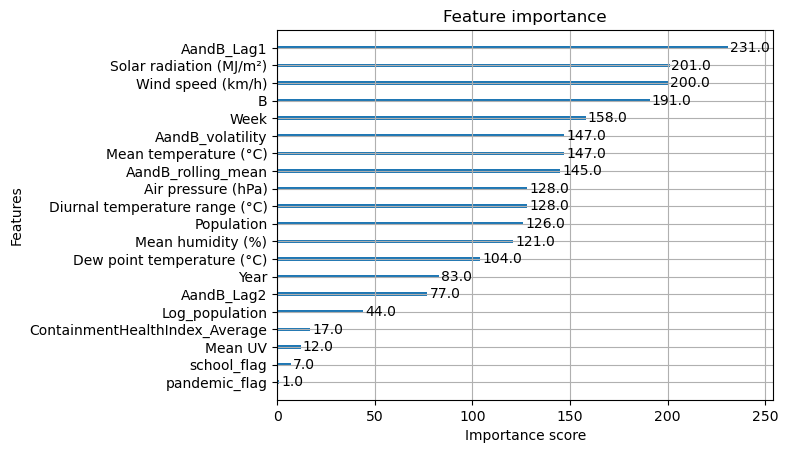

In [10]:
xgbl.plot_importance(model)
plt.show()

In [12]:
# xgbl.plot_tree(model, num_tree=2)